<a href="https://colab.research.google.com/github/beast-gif/pattern-solving/blob/main/similarity_pipeline_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q -U deepagents langchain-openai

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.6/58.6 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 361.1/361.1 kB 20.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.4/146.4 kB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.4/170.4 kB 18.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.5/65.5 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 573.8/573.8 kB 31.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.9/81.9 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 869.0/869.0 kB 57.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.4/43.4 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 94.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 77.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.9/267.9 kB 29.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not curr

## Config

In [ ]:
import os, json, math, re, random, asyncio
from pathlib import Path
from google.colab import userdata, drive

drive.mount('/content/drive')
WORK_DIR = Path('/content/drive/MyDrive/similarity_pipeline')
WORK_DIR.mkdir(parents=True, exist_ok=True)

ITEMS_PATH    = WORK_DIR / 'items_modi.json'
SCHEMA_PATH   = WORK_DIR / 'schema.json'
PROFILES_PATH = WORK_DIR / 'profiles.json'
REPORT_PATH   = WORK_DIR / 'report.md'

# ---- LLM: Velona (OpenAI-compatible) ----
API_KEY        = userdata.get('VELONA_API_KEY')
BASE_URL       = 'https://velona.in/v1'
MODEL          = 'anthropic/claude-sonnet-5.5'   # schema proposal + explainer (2 calls)
PROFILER_MODEL = 'anthropic/claude-haiku-5.5'    # Stage 4 profiling (most of the calls, cheaper)

# ---- Stage 2: schema ----
SCHEMA_SAMPLE_SIZE = 20      # items shown to the schema agent
N_FEATURES_HINT    = '5-8'   # how many features to propose
SAMPLE_WORDS       = 250     # each sample item is clipped to this many words

# ---- Stage 3: agent sizing ----
CONTEXT_TOKENS        = 200_000  # C: model context window (Claude models)
SAFETY                = 0.5      # s: use only this fraction of the context
AGENT_OVERHEAD_TOKENS = 6_000    # deep agent built-in prompt + tool definitions (rough)
K_MAX                 = 8        # cap items per agent (long structured outputs get unreliable)
W_MAX                 = 5        # max agents running at once (rate limit)
MAX_RETRIES           = 2

# ---- Stage 5: comparison ----
TOP_K_PAIRS         = 15
EXCLUDE_SAME_SOURCE = False   # True = only compare items from different sources
SEED                = 42

Mounted at /content/drive


## Stage 1 — Load items
If `items.json` isn't in the Drive folder yet, this cell asks you to upload it.

In [ ]:
if not ITEMS_PATH.exists():
    from google.colab import files
    uploaded = files.upload()
    ITEMS_PATH.write_bytes(uploaded[next(iter(uploaded))])

items = json.load(open(ITEMS_PATH))
ID2ITEM = {it['id']: it for it in items}
N = len(items)
print(f'{N} items loaded')
for it in items[:5]:
    print(it['id'], '|', it['title'], '|', len(it['text'].split()), 'words')

65 items loaded
1 | Fasting (1/4) | 491 words
2 | Fasting (2/4) | 322 words
3 | Fasting (3/4) | 315 words
4 | Fasting (4/4) | 331 words
5 | Early life (1/4) | 423 words


## LLM and agent helpers

In [ ]:
from langchain_openai import ChatOpenAI
from deepagents import create_deep_agent
from pydantic import BaseModel, Field, create_model

llm          = ChatOpenAI(model=MODEL,          base_url=BASE_URL, api_key=API_KEY, temperature=0, max_retries=3)
profiler_llm = ChatOpenAI(model=PROFILER_MODEL, base_url=BASE_URL, api_key=API_KEY, temperature=0, max_retries=3)

def est_tokens(text: str) -> int:
    # rough: ~4 characters per token
    return max(1, len(text) // 4)

def clip_words(text: str, n: int) -> str:
    w = text.split()
    return ' '.join(w[:n]) + (' ...' if len(w) > n else '')

def _message_text(msg) -> str:
    c = msg.content
    if isinstance(c, list):
        c = ''.join(p.get('text', '') if isinstance(p, dict) else str(p) for p in c)
    return c

def _extract_json(text: str):
    m = re.search(r'```(?:json)?\s*(.*?)```', text, re.S)
    if m:
        text = m.group(1)
    start, end = text.find('{'), text.rfind('}')
    return json.loads(text[start:end + 1])

from langchain.agents.structured_output import ProviderStrategy

_paths_seen = set()
def _note_path(schema, path):
    if (schema.__name__, path) not in _paths_seen:
        _paths_seen.add((schema.__name__, path))
        print(f'[{schema.__name__}] structured output via: {path}')

def _as_schema(schema, raw):
    if isinstance(raw, schema):
        return raw
    if isinstance(raw, BaseModel):
        raw = raw.model_dump()
    return schema.model_validate(raw)

async def run_structured(system_prompt: str, user_msg: str, schema, model=None):
    # Returns an instance of `schema`. Velona + Sonnet rejects forced tool calls,
    # so structured output uses native json_schema, with two fallbacks.
    model = model or llm
    errors = []

    # 1. deep agent, native json_schema output
    try:
        agent = create_deep_agent(model=model, system_prompt=system_prompt,
                                  response_format=ProviderStrategy(schema))
        res = await agent.ainvoke({'messages': [{'role': 'user', 'content': user_msg}]})
        out = res.get('structured_response')
        if out is None:
            out = _extract_json(_message_text(res['messages'][-1]))
        result = _as_schema(schema, out)
        _note_path(schema, 'deep agent (json_schema)')
        return result
    except Exception as e:
        errors.append(f'deep agent: {type(e).__name__}: {str(e)[:150]}')

    # 2. direct model call, native json_schema output
    try:
        out = await model.with_structured_output(schema, method='json_schema').ainvoke(
            [('system', system_prompt), ('user', user_msg)])
        result = _as_schema(schema, out)
        _note_path(schema, 'direct json_schema (deep agent failed)')
        return result
    except Exception as e:
        errors.append(f'direct json_schema: {type(e).__name__}: {str(e)[:150]}')

    # 3. plain chat: ask for JSON, then validate with Pydantic
    try:
        prompt = (user_msg + '\n\nReturn ONLY a JSON object that matches this JSON schema, with no other text:\n'
                  + json.dumps(schema.model_json_schema()))
        msg = await model.ainvoke([('system', system_prompt), ('user', prompt)])
        result = _as_schema(schema, _extract_json(_message_text(msg)))
        _note_path(schema, 'plain JSON (other paths failed)')
        return result
    except Exception as e:
        errors.append(f'plain JSON: {type(e).__name__}: {str(e)[:150]}')

    raise RuntimeError(' || '.join(errors))

async def run_text(system_prompt: str, user_msg: str) -> str:
    agent = create_deep_agent(model=llm, system_prompt=system_prompt)
    res = await agent.ainvoke({'messages': [{'role': 'user', 'content': user_msg}]})
    return _message_text(res['messages'][-1])

## Stage 2 — Propose the schema
One deep agent reads a sample and proposes features. If `schema.json` already exists in Drive, it is reused instead (delete it to propose again).

In [ ]:
class FeatureSpec(BaseModel):
    name: str        = Field(description='short snake_case feature name')
    description: str = Field(description='what the feature measures, one sentence')
    anchor_0: str    = Field(description='what a score of 0 means')
    anchor_05: str   = Field(description='what a score of 0.5 means')
    anchor_1: str    = Field(description='what a score of 1 means')

class SchemaProposal(BaseModel):
    features: list[FeatureSpec]

SCHEMA_SYSTEM = f'''You design a feature schema for comparing items. Each item is an idea, step or
practice described in a transcript. Read the sample items and propose {N_FEATURES_HINT} features.

Each feature must:
- apply to EVERY item (any item can be scored on it),
- vary across items (not the same score for all),
- not overlap with another feature,
- describe the CONTENT of the idea, not the speaker, source or writing style,
- be scorable from 0 to 1 with clear anchors for 0, 0.5 and 1.'''

if SCHEMA_PATH.exists():
    schema_features = json.load(open(SCHEMA_PATH))
    print('Loaded existing schema from Drive')
else:
    random.seed(SEED)
    sample = random.sample(items, min(SCHEMA_SAMPLE_SIZE, N))
    sample_txt = '\n\n'.join(f"[{it['id']}] {it['title']}\n{clip_words(it['text'], SAMPLE_WORDS)}" for it in sample)
    proposal = await run_structured(SCHEMA_SYSTEM, 'Sample items:\n\n' + sample_txt, SchemaProposal)
    schema_features = [f.model_dump() for f in proposal.features]

for f in schema_features:
    print(f"- {f['name']}: {f['description']}")
    print(f"    0 = {f['anchor_0']} | 0.5 = {f['anchor_05']} | 1 = {f['anchor_1']}")

[SchemaProposal] structured output via: deep agent (json_schema)
- actionability_for_listener: How directly the idea can be applied by a listener as a concrete practice or advice, versus being a personal story or description.
    0 = Purely biographical or descriptive; nothing a listener could apply (e.g. a personal anecdote or closing pleasantries). | 0.5 = Contains an implicit lesson or habit the listener could adopt, but it is not spelled out as a step. | 1 = Explicit, concrete guidance or a practice the listener can directly follow (e.g. specific advice on how to learn or cope).
- spiritual_religious_orientation: The degree to which the idea concerns spirituality, religion, ritual or inner transcendence.
    0 = Entirely secular, with no spiritual or religious content. | 0.5 = Spirituality is a notable but secondary element alongside other themes. | 1 = Centered on spiritual practice, ritual, faith or religious tradition (e.g. mantras, devotion).
- personal_discipline_and_self_mast

## Review the schema
Edit `schema_features` here if needed (drop vague features, merge overlapping ones, reword anchors). Leave this cell as is to accept the proposal.

In [ ]:
# Examples:
# schema_features = [f for f in schema_features if f['name'] != 'some_vague_feature']
# schema_features[0]['anchor_1'] = 'clearer wording'

## Freeze the schema
Fixes the names, meanings, 0–1 range and order. Every profiler gets exactly this model.

In [ ]:
def snake(s: str) -> str:
    s = re.sub(r'[^0-9a-zA-Z]+', '_', s).strip('_').lower()
    return s if s and not s[0].isdigit() else 'f_' + s

seen = set()
for f in schema_features:
    f['name'] = snake(f['name'])
    assert f['name'] not in seen, f"duplicate feature name: {f['name']}"
    seen.add(f['name'])

json.dump(schema_features, open(SCHEMA_PATH, 'w'), indent=2)

FEATURES = [f['name'] for f in schema_features]   # fixed vector order

fields = {
    'id':   (int, Field(description="the item's id exactly as given")),
    'tags': (list[str], Field(description="3-5 short lowercase tags for the item's main ideas")),
}
for f in schema_features:
    fields[f['name']] = (float, Field(
        ge=0, le=1,
        description=f"{f['description']} | 0 = {f['anchor_0']}; 0.5 = {f['anchor_05']}; 1 = {f['anchor_1']}"))
    fields[f['name'] + '_evidence'] = (str, Field(
        description=f"short phrase from the item's text (max 12 words) justifying the {f['name']} score"))

Profile       = create_model('Profile', **fields)
BatchProfiles = create_model('BatchProfiles', profiles=(list[Profile], Field(description='one profile per input item, same ids')))

RUBRIC = '\n'.join(
    f"- {f['name']}: {f['description']} (0 = {f['anchor_0']}; 0.5 = {f['anchor_05']}; 1 = {f['anchor_1']})"
    for f in schema_features)
print('Frozen features (vector order):', FEATURES)

Frozen features (vector order): ['actionability_for_listener', 'spiritual_religious_orientation', 'personal_discipline_and_self_mastery', 'societal_or_national_scope', 'hardship_and_adversity', 'service_and_purpose_orientation', 'knowledge_learning_and_innovation', 'abstract_vs_concrete_detail']


## Stage 3 — How many agents
`k = ⌊(C·s − P) / t_max⌋` items per agent (using the **longest** item, since lengths vary), then `W = min(⌈N / k⌉, W_max)` agents at once.

In [ ]:
PROFILER_SYSTEM = f'''You profile items against a FIXED feature schema.

Rules:
- Score every item on every feature from 0 to 1, using the anchors exactly.
- Judge each item ONLY from its own text. Other items in the same message must not influence its scores.
- For each score, give a short evidence phrase taken from that item's text (max 12 words).
- Return exactly one profile per input item, with the same id.

Features:
{RUBRIC}'''

P = est_tokens(PROFILER_SYSTEM) + AGENT_OVERHEAD_TOKENS
out_per_item = 40 + len(FEATURES) * 30          # rough output tokens per profile
t_max = max(est_tokens(it['text']) for it in items) + out_per_item

k_formula = math.floor((CONTEXT_TOKENS * SAFETY - P) / t_max)
k = max(1, min(k_formula, K_MAX))
n_batches = math.ceil(N / k)
W = min(n_batches, W_MAX)

print(f'P = {P} tokens, t_max = {t_max} tokens')
print(f'k = floor(({CONTEXT_TOKENS} x {SAFETY} - {P}) / {t_max}) = {k_formula} -> capped at K_MAX -> k = {k}')
print(f'batches = ceil({N} / {k}) = {n_batches}, running W = min({n_batches}, {W_MAX}) = {W} at once')
est_total = sum(est_tokens(it['text']) + out_per_item for it in items) + n_batches * P
print(f'estimated tokens for Stage 4: ~{est_total:,}')

P = 6890 tokens, t_max = 1067 tokens
k = floor((200000 x 0.5 - 6890) / 1067) = 87 -> capped at K_MAX -> k = 8
batches = ceil(65 / 8) = 9, running W = min(9, 5) = 5 at once
estimated tokens for Stage 4: ~110,835


## Stage 4 — Profile all items in parallel
Resumable: profiles are saved to Drive after every batch, and already-profiled items are skipped on re-run. Items missing after the batch run are retried one at a time.

In [ ]:
profiles = json.load(open(PROFILES_PATH)) if PROFILES_PATH.exists() else {}   # keys: str(id)

def save_profiles():
    json.dump(profiles, open(PROFILES_PATH, 'w'), indent=2)

def batch_message(batch):
    return 'Profile each of these items:\n\n' + '\n\n'.join(
        f'<item id="{it["id"]}">\n{it["text"]}\n</item>' for it in batch)

async def profile_batch(batch, sem, label):
    wanted = {it['id'] for it in batch}
    async with sem:
        for attempt in range(MAX_RETRIES + 1):
            try:
                res = await run_structured(PROFILER_SYSTEM, batch_message(batch), BatchProfiles, model=profiler_llm)
                got = {p.id: p.model_dump() for p in res.profiles if p.id in wanted}
                for i, p in got.items():
                    profiles[str(i)] = p
                save_profiles()
                print(f'{label}: {len(got)}/{len(batch)} profiled')
                return
            except Exception as e:
                print(f'{label}: attempt {attempt + 1} failed: {type(e).__name__}: {str(e)[:200]}')
        print(f'{label}: giving up')

todo = [it for it in items if str(it['id']) not in profiles]
batches = [todo[i:i + k] for i in range(0, len(todo), k)]
print(f'{len(todo)} items to profile in {len(batches)} batches, {W} at once')

sem = asyncio.Semaphore(W)
await asyncio.gather(*[profile_batch(b, sem, f'batch {n + 1}') for n, b in enumerate(batches)])

missing = [it for it in items if str(it['id']) not in profiles]
if missing:
    print(f'Retrying {len(missing)} missing items one at a time')
    await asyncio.gather(*[profile_batch([it], sem, f'item {it["id"]}') for it in missing])

missing = [it['id'] for it in items if str(it['id']) not in profiles]
print(f'Done: {len(profiles)}/{N} profiled' + (f'; still missing: {missing}' if missing else ''))

65 items to profile in 9 batches, 5 at once
[BatchProfiles] structured output via: deep agent (json_schema)
batch 5: 8/8 profiled
batch 4: 8/8 profiled
batch 1: 8/8 profiled
batch 3: 8/8 profiled
batch 9: 1/1 profiled
batch 2: 8/8 profiled
batch 6: 8/8 profiled
batch 8: 8/8 profiled
batch 7: 8/8 profiled
Done: 65/65 profiled


## Stage 5 — Compare all pairs (PyTorch, no LLM)

In [ ]:
import torch
import torch.nn.functional as F

device = 'cuda' if torch.cuda.is_available() else 'cpu'
ids = [it['id'] for it in items if str(it['id']) in profiles]
n = len(ids)

# Vectors built from FEATURES order, never from the agent's output order
X = torch.tensor([[float(profiles[str(i)][f]) for f in FEATURES] for i in ids],
                 dtype=torch.float32, device=device)            # (n, d)

Xn = F.normalize(X, p=2, dim=1)                                  # row / its norm
S = Xn @ Xn.T                                                    # S[a, b] = cosine

iu, ju = torch.triu_indices(n, n, offset=1, device=device)       # each pair once
scores = S[iu, ju].clone()

if EXCLUDE_SAME_SOURCE:
    src = [ID2ITEM[i]['source'] for i in ids]
    same = torch.tensor([src[a] == src[b] for a, b in zip(iu.tolist(), ju.tolist())], device=device)
    scores[same] = -1.0

top = torch.topk(scores, k=min(TOP_K_PAIRS, scores.numel()))

def jaccard(a, b):
    A = {t.lower().strip() for t in a}; B = {t.lower().strip() for t in b}
    return len(A & B) / len(A | B) if A | B else 0.0

top_pairs = []
for val, t in zip(top.values.tolist(), top.indices.tolist()):
    a, b = iu[t].item(), ju[t].item()
    prod = X[a] * X[b]                                           # A_i x B_i
    dot = prod.sum().item()
    share = (prod / dot).tolist() if dot > 0 else [0.0] * len(FEATURES)
    diff = (X[a] - X[b]).abs().tolist()
    ia, ib = ids[a], ids[b]
    pa, pb = profiles[str(ia)], profiles[str(ib)]
    top_pairs.append({
        'a': ia, 'b': ib, 'cosine': val,
        'contributions': sorted(zip(FEATURES, share), key=lambda x: -x[1]),
        'biggest_difference': max(zip(FEATURES, diff), key=lambda x: x[1]),
        'common_tags': sorted({t.lower() for t in pa['tags']} & {t.lower() for t in pb['tags']}),
        'jaccard': jaccard(pa['tags'], pb['tags']),
    })

for p in top_pairs:
    A, B = ID2ITEM[p['a']], ID2ITEM[p['b']]
    print(f"[{p['a']}] {A['title']}  <->  [{p['b']}] {B['title']}")
    print(f"   cosine = {p['cosine']:.3f} | tag Jaccard = {p['jaccard']:.2f} | common tags: {p['common_tags']}")
    print('   contributions: ' + ', '.join(f'{f} {s:.0%}' for f, s in p['contributions'] if s >= 0.05))
    f, d = p['biggest_difference']
    print(f'   biggest difference: {f} (|diff| = {d:.2f})\n')

[31] Donald Trump (3/4)  <->  [32] Donald Trump (4/4)
   cosine = 1.000 | tag Jaccard = 0.00 | common tags: []
   contributions: societal_or_national_scope 57%, actionability_for_listener 14%, service_and_purpose_orientation 14%, knowledge_learning_and_innovation 14%
   biggest difference: actionability_for_listener (|diff| = 0.00)

[36] Gujarat riots in 2002 (2/6)  <->  [37] Gujarat riots in 2002 (3/6)
   cosine = 1.000 | tag Jaccard = 0.00 | common tags: []
   contributions: societal_or_national_scope 44%, hardship_and_adversity 44%, service_and_purpose_orientation 11%
   biggest difference: actionability_for_listener (|diff| = 0.00)

[49] Decision-making process (1/3)  <->  [54] AI (3/4)
   cosine = 1.000 | tag Jaccard = 0.00 | common tags: []
   contributions: societal_or_national_scope 44%, actionability_for_listener 11%, personal_discipline_and_self_mastery 11%, service_and_purpose_orientation 11%, knowledge_learning_and_innovation 11%, abstract_vs_concrete_detail 11%
   biggest 

### Similarity heatmap

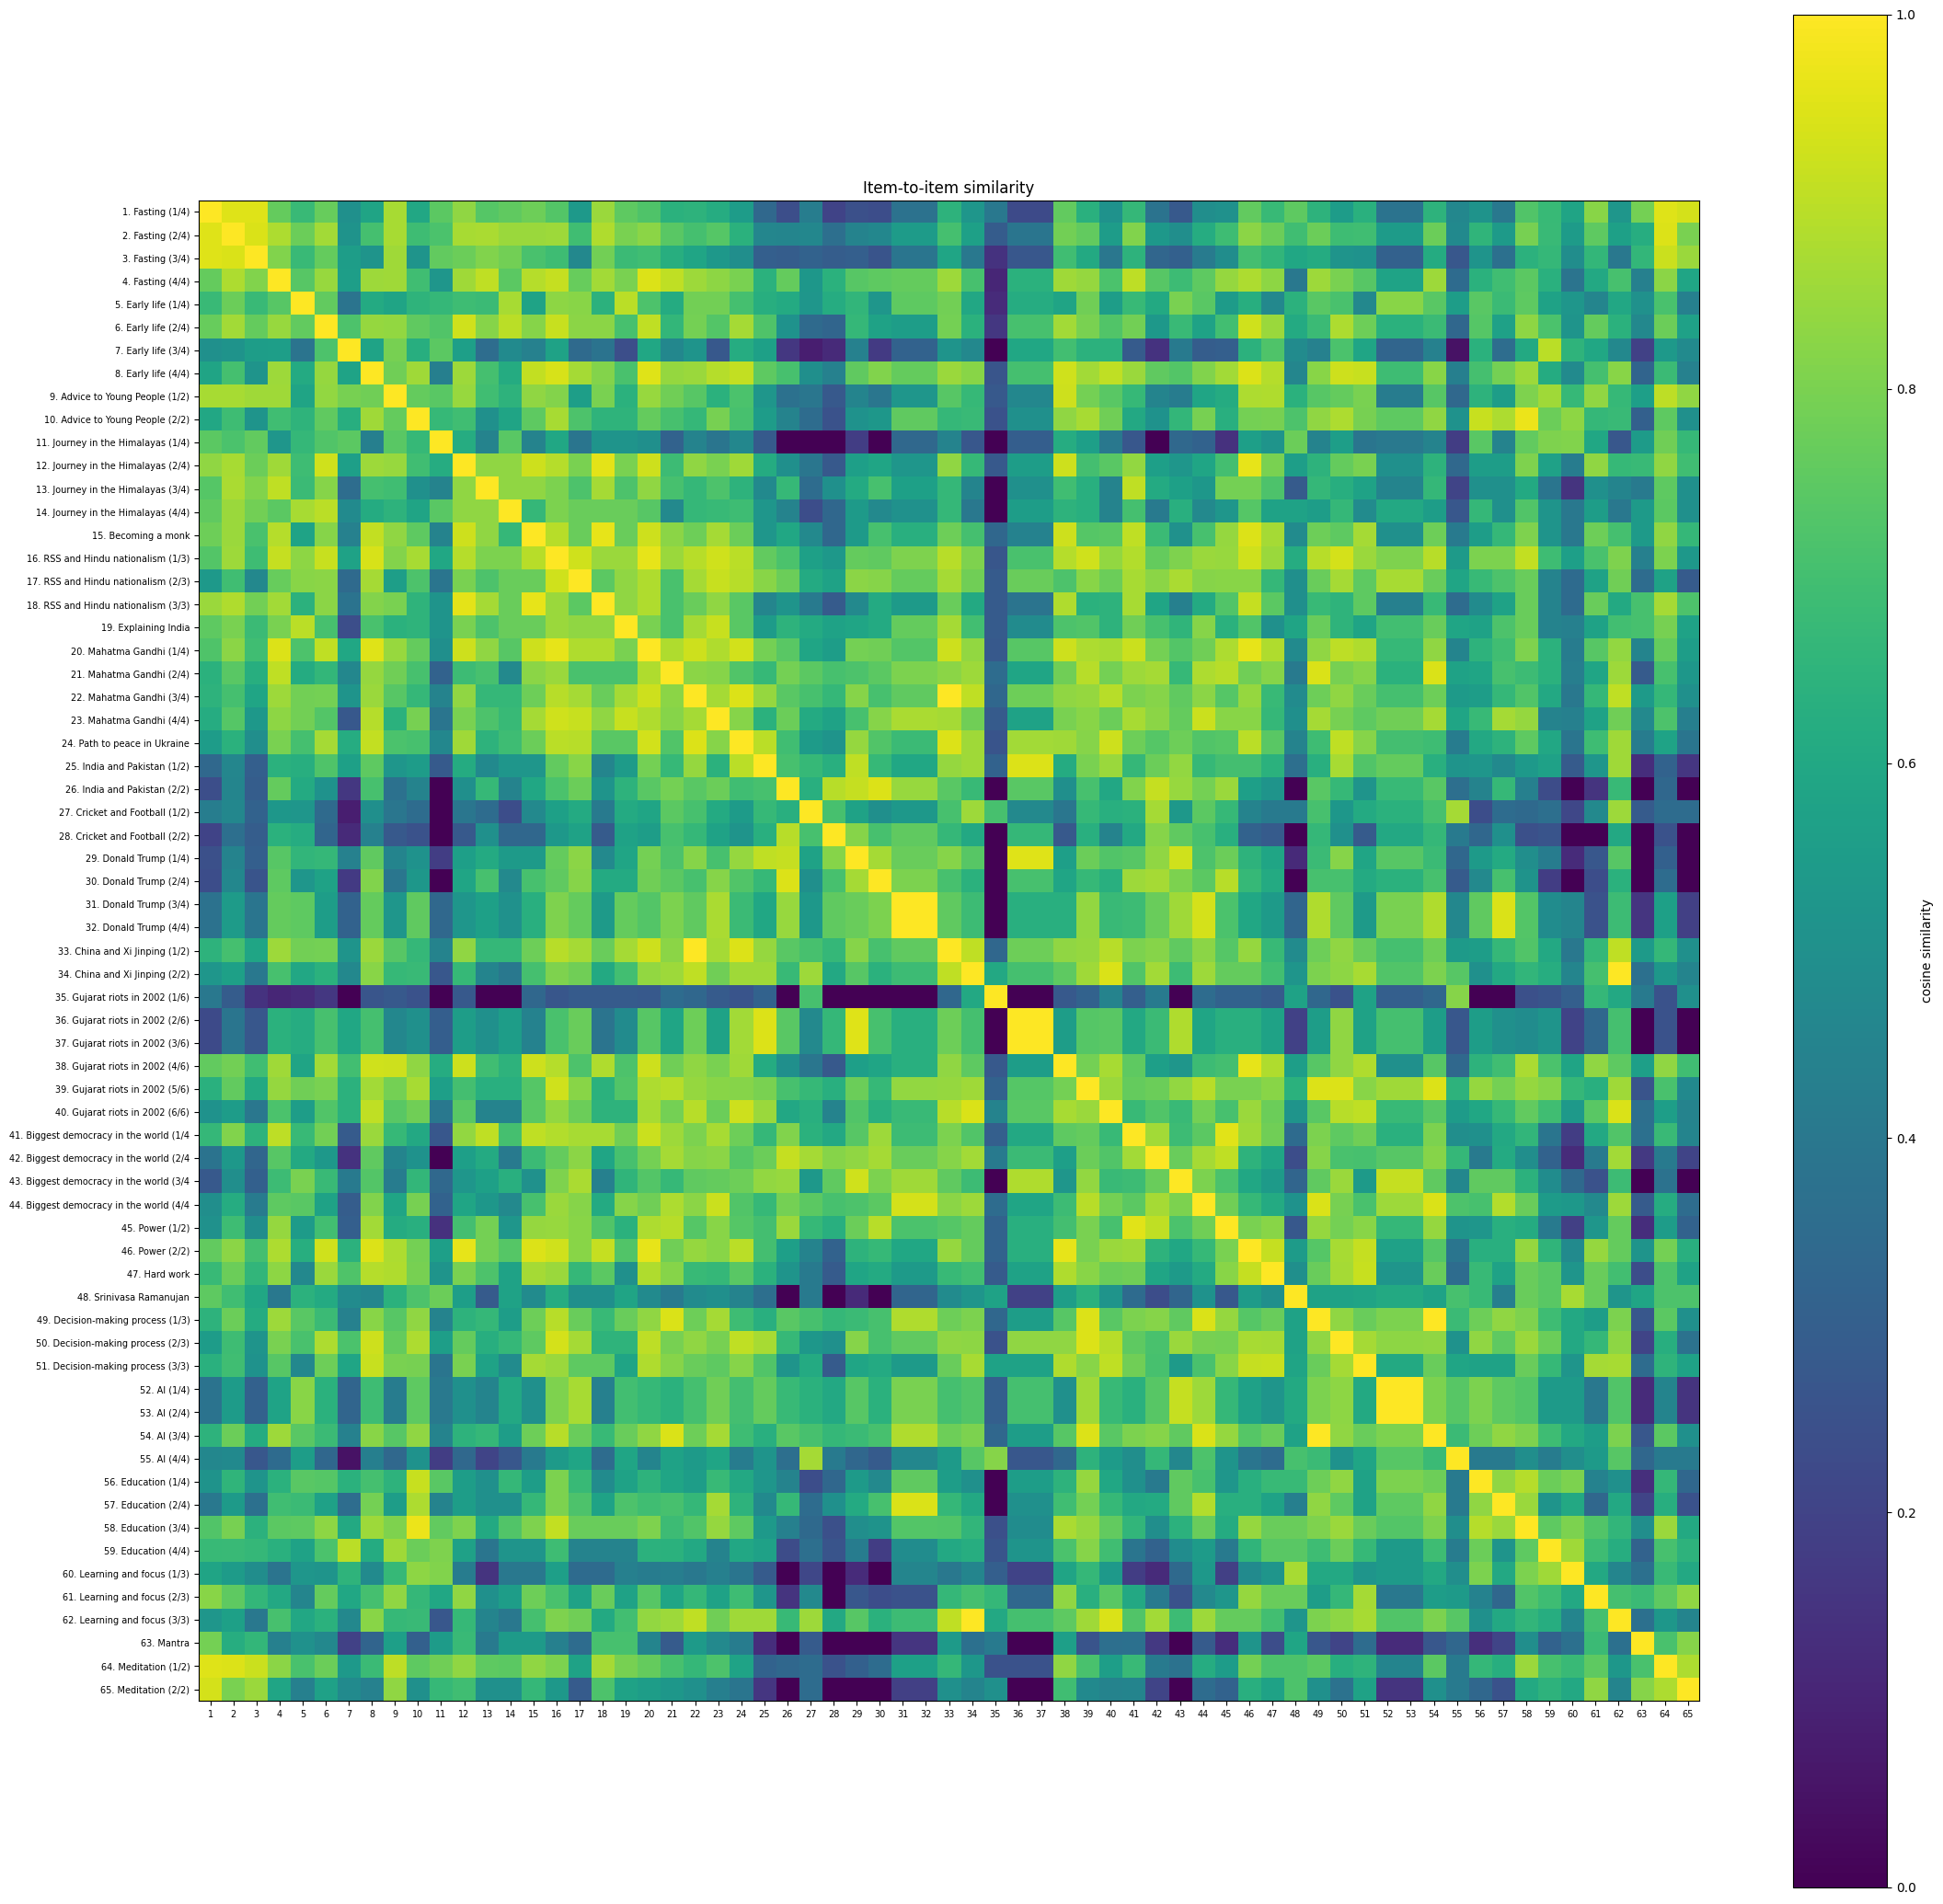

In [ ]:
import matplotlib.pyplot as plt

S_cpu = S.cpu().numpy()
labels = [f"{i}. {ID2ITEM[i]['title'][:35]}" for i in ids]
fig, ax = plt.subplots(figsize=(max(8, n * 0.35), max(7, n * 0.32)))
im = ax.imshow(S_cpu, cmap='viridis', vmin=0, vmax=1)
ax.set_xticks(range(n)); ax.set_xticklabels([str(i) for i in ids], fontsize=7)
ax.set_yticks(range(n)); ax.set_yticklabels(labels, fontsize=7)
fig.colorbar(im, ax=ax, label='cosine similarity')
ax.set_title('Item-to-item similarity')
plt.tight_layout(); plt.show()

### Sanity check: the five-step process
The same five steps appear in three sources. Matching steps should rank among the most similar pairs. (Specific to this dataset's item ids; skip for other datasets.)

In [ ]:
FIVE_STEP_GROUPS = {
    'question requirements': [2, 15, 31],
    'delete':                [3, 16, 32],
    'simplify / optimize':   [4, 17, 33],
    'speed up':              [6, 18, 34],
    'automate':              [7, 19, 35],
}
pos = {i: r for r, i in enumerate(ids)}
all_scores = sorted(S[iu, ju].tolist(), reverse=True)
total_pairs = len(all_scores)

for name, g in FIVE_STEP_GROUPS.items():
    g = [i for i in g if i in pos]
    for x in range(len(g)):
        for y in range(x + 1, len(g)):
            s = S[pos[g[x]], pos[g[y]]].item()
            rank = sum(v > s for v in all_scores) + 1
            print(f'{name:22s} [{g[x]}] vs [{g[y]}]: cosine {s:.3f}, rank {rank}/{total_pairs}')
print(f'\nmean cosine over all pairs: {sum(all_scores) / total_pairs:.3f}')

question requirements  [2] vs [15]: cosine 0.849, rank 270/2080
question requirements  [2] vs [31]: cosine 0.550, rank 1462/2080
question requirements  [15] vs [31]: cosine 0.630, rank 1215/2080
delete                 [3] vs [16]: cosine 0.690, rank 973/2080
delete                 [3] vs [32]: cosine 0.390, rank 1803/2080
delete                 [16] vs [32]: cosine 0.808, rank 430/2080
simplify / optimize    [4] vs [17]: cosine 0.769, rank 619/2080
simplify / optimize    [4] vs [33]: cosine 0.853, rank 244/2080
simplify / optimize    [17] vs [33]: cosine 0.866, rank 184/2080
speed up               [6] vs [18]: cosine 0.825, rank 372/2080
speed up               [6] vs [34]: cosine 0.640, rank 1159/2080
speed up               [18] vs [34]: cosine 0.609, rank 1265/2080
automate               [7] vs [19]: cosine 0.242, rank 1984/2080
automate               [7] vs [35]: cosine 0.000, rank 2040/2080
automate               [19] vs [35]: cosine 0.289, rank 1924/2080

mean cosine over all pairs

## Stage 6 — Explain the top pairs
The explainer gets only the computed numbers and evidence phrases, and is told not to recompute anything.

In [ ]:
EXPLAINER_SYSTEM = '''You explain why pairs of items are similar. The similarity numbers were computed
by code and are correct: do NOT recompute or change them. For each pair, state in plain words:
1. the common thing (from the features with the largest contributions and the common tags),
2. the main difference (from the biggest-difference feature).
Ground every claim in the evidence phrases given. Then finish with a short overview of the
patterns across all pairs (e.g. which ideas keep recurring across sources). Use Markdown.'''

def pair_block(p):
    A, B = ID2ITEM[p['a']], ID2ITEM[p['b']]
    pa, pb = profiles[str(p['a'])], profiles[str(p['b'])]
    top_feats = [f for f, s in p['contributions'][:3]]
    lines = [f"### [{p['a']}] {A['title']} ({A['source']})  vs  [{p['b']}] {B['title']} ({B['source']})",
             f"cosine = {p['cosine']:.3f}; tag Jaccard = {p['jaccard']:.2f}; common tags = {p['common_tags']}",
             'contributions: ' + ', '.join(f'{f} {s:.0%}' for f, s in p['contributions'])]
    for f in top_feats:
        lines.append(f"- {f}: A = {pa[f]:.2f} ('{pa[f + '_evidence']}'), B = {pb[f]:.2f} ('{pb[f + '_evidence']}')")
    f, d = p['biggest_difference']
    lines.append(f"- biggest difference: {f}: A = {pa[f]:.2f} ('{pa[f + '_evidence']}'), B = {pb[f]:.2f} ('{pb[f + '_evidence']}')")
    return '\n'.join(lines)

explainer_msg = 'Feature schema:\n' + RUBRIC + '\n\nTop pairs:\n\n' + '\n\n'.join(pair_block(p) for p in top_pairs)
report = await run_text(EXPLAINER_SYSTEM, explainer_msg)

REPORT_PATH.write_text(report)
from IPython.display import Markdown, display
display(Markdown(report))
print(f'\nSaved to {REPORT_PATH}')

# Why these pairs are similar

All pairs come from Lex Fridman podcast #460. I haven't recomputed any numbers. Pairs with cosine 1.000 and tag Jaccard 0.00 share a feature profile but have no common tags. For those, the similarity comes from matching feature scores, not from shared topics.

---

### [31] Donald Trump (3/4) vs [32] Donald Trump (4/4), cosine 1.000
- **Common thing:** Both are about government efficiency at national scale. A cites "government savings of trillions of rupees, global DOGE discussions". B cites "removing 40,000 compliances and 1500 laws". Both also carry an implicit lesson about cutting waste with technology.
- **Main difference:** The largest-difference feature, actionability, is 0.50 for both. The gap is in the means. A removes duplicate records to stop leakage. B cuts unnecessary rules and uses online procurement.

### [36] Gujarat riots (2/6) vs [37] Gujarat riots (3/6), cosine 1.000
- **Common thing:** Both are nation- or state-scale accounts centred on adversity. A has "terror attacks, earthquake and fear-filled turmoil". B has the "Godhra burning tragedy and communal riots". Both give service or responsibility a side role.
- **Main difference:** Neither offers listener advice (both 0.00). A is a "chronological account of events". B is a "personal defense of record".

### [49] Decision-making (1/3) vs [54] AI (3/4), cosine 1.000
- **Common thing:** Both put the nation first. A says "my country first". B says "Indian talent gains global respect". Both also give a mild, implicit lesson.
- **Main difference:** Both score 0.50 on actionability. A's advice is to picture the poorest person's face before deciding. B's is to give your best wherever you are.

### [34] China and Xi Jinping (2/2) vs [62] Learning and focus (3/3), cosine 1.000
- **Common thing:** Both are abstract, world-scale reflections. A covers "world order, interdependence". B covers the "history of mankind". Both nudge the listener toward a positive choice.
- **Main difference:** A's nudge is to let go of conflict and move toward cooperation. B's is to "gravitate toward the bright side".

### [52] AI (1/4) vs [53] AI (2/4), cosine 1.000
- **Common thing:** Both are about national AI and technology. A centres on "AI development and India's AI talent pool". B covers "GPU access... national AI and 5G efforts". Both also mention India being perceived as lagging behind.
- **Main difference:** Neither gives advice (both 0.00). A asserts that AI is incomplete without India. B describes India's AI and 5G efforts.

### [22] Mahatma Gandhi (3/4) vs [33] China and Xi Jinping (1/2), cosine 1.000
- **Common thing:** Both are about relations between nations. A covers "1.4 billion Indians, world leaders and foreign policy". B covers "bilateral relations between two nations". Both touch spiritual heritage, through Vedic tradition and Buddhism.
- **Main difference:** Both score 0.50 on actionability. A's lesson is to avoid belittling others while standing firm. B's is to prefer dialogue over discord.

### [10] Advice to Young People (2/2) vs [58] Education (3/4), cosine 0.970
- **Common thing:** These are the strongest content match. They share the tags *continuous learning* and *purpose*. Both give explicit advice: "never let the student within them die" and "improve skills constantly". Both also tie life to giving or a greater purpose.
- **Main difference:** B has some spiritual content ("God has given everyone unique capabilities", 0.50). A has none.

### [38] Gujarat riots (4/6), [12] Himalayas (2/4) and [20] Gandhi (1/4), each vs [46] Power (2/2), cosine 0.965
- **Common thing:** In all three, the link to Power (2/2) is service. B says "Serving the people is serving the divine". The others say:
  - [38]: "continue serving my country with complete dedication".
  - [12]: "true contentment comes from giving".
  - [20]: "Gave up comforts to devote his life to serving".
- **Main differences:**
  - [38] gives the most explicit advice (1.00): welcome criticism, and tell genuine criticism from allegations. B's advice is the implicit habit of calling elderly volunteers.
  - [12] is more spiritual (1.00): meditation before Kali's idol. B scores 0.50.
  - [20] is wider in scope (1.00): a mass movement for independence. B is 0.50 (personal calls to volunteers).

### [16] RSS (1/3) vs [20] Gandhi (1/4), cosine 0.964
- **Common thing:** Both put nation and service first. A says "the nation is everything". B has a "mass movement awakening the nation". Both say to act for a larger cause.
- **Main difference:** A touches learning ("study with the goal of learning enough to contribute", 0.50). B has none.

### [15] Becoming a monk vs [18] RSS (3/3), cosine 0.962
- **Common thing:** Both centre on a service-driven life with a spiritual base. A says "Every action is dedicated to serving others". B has a "service-driven philosophy".
- **Main difference:** B is more spiritual (1.00: saints, Swami Atmasthananda). A is 0.50 ("unwavering spiritual commitment").

### [12] Himalayas (2/4) vs [18] RSS (3/3), cosine 0.961
- **Common thing:** Both combine spirituality and service. A has Kali meditation and "contentment comes from giving". B has saints and a "life of purpose".
- **Main difference:** A includes some adversity ("His mother was unwell", 0.50). B has none.

### [41] Biggest democracy (1/4) vs [45] Power (1/2), cosine 0.953
- **Common thing:** They share the tags *democracy* and *service*. Both describe the leader as a servant of the people. A says "Like a devoted priest... serving the people". B says "I am a humble servant".
- **Main difference:** A has a spiritual strand ("I revere my nation as the Divine"). B is secular.

### [1] Fasting (1/4) vs [2] Fasting (2/4), cosine 0.953
- **Common thing:** Both treat fasting as discipline and devotion. A says it cultivates "discipline and balance". B calls it "self-discipline" and "an act of devotion".
- **Main difference:** A is slightly more abstract (0.60), a general philosophy with sensory examples. B is more concrete (0.40), with a school memory.

---

## Overview of patterns

- **Nation-scale framing dominates the 1.000 pairs.** National scope accounts for 36–57% of the similarity in each. Topics as different as Trump, China, AI and Gandhi match because each is about India's place in the world or in government.
- **Service as a higher purpose recurs across sources.** The Power, Gandhi, RSS, monk, Himalayas and democracy items all use the "serving people is serving God" idea.
- **Spirituality blends with duty.** Divine language is attached to public service, not only to personal practice.
- **Advice is mostly implicit.** Most pairs score 0.50 on actionability. The explicit, 1.00 advice appears in the youth and education pair and in the Gujarat criticism passage.
- **Adversity shows up as the setting for resilience.** It appears in the riots and the Himalayas passages, and the Fasting pair covers the discipline side of the same theme.


Saved to /content/drive/MyDrive/similarity_pipeline/report.md
